We continue with your actual dataset, which has these columns:

Car_ID, Brand, Model, Year, Age_Years, Price, Kilometers_Driven, Fuel_Type, Transmission, Owner_Type, Mileage_kmpl, Engine_CC, Power_bhp, Seats, Color, City

In [ ]:
import pandas as pd

df = pd.read_csv('used_cars_dataset.csv')
print(df.head())
print(df.shape)

   Car_ID       Brand    Model  Year  Age_Years    Price  Kilometers_Driven  \
0       1         BMW       X5  2019          7  7134000              86551   
1       2         Kia  Picanto  2025          1  4025000               8577   
2       3     Hyundai   Santro  2011         15   300000             177666   
3       4       Honda   Accord  2008         18   300000             217370   
4       5  Volkswagen     Golf  2013         13   342000             145065   

  Fuel_Type Transmission            Owner_Type  Mileage_kmpl  Engine_CC  \
0    Petrol       Manual           Third Owner          16.4       2500   
1    Petrol       Manual  Fourth & Above Owner          11.3       1300   
2    Diesel       Manual           First Owner          14.9       1300   
3    Petrol       Manual           First Owner          12.6       1200   
4    Petrol       Manual           First Owner          18.0       1300   

   Power_BHP  Seats  Color        City  
0      190.1      5  Green  Faisa

**First: Which Columns Are Nominal Here?**

From Lecture 21, recall the test: "Does the order of categories matter?" Let's apply it to every categorical column in your dataset:

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values -> {df[col].unique()[:5]}")

Brand: 12 unique values -> ['BMW' 'Kia' 'Hyundai' 'Honda' 'Volkswagen']
Model: 51 unique values -> ['X5' 'Picanto' 'Santro' 'Accord' 'Golf']
Fuel_Type: 5 unique values -> ['Petrol' 'Diesel' 'Hybrid' 'CNG' 'Electric']
Transmission: 2 unique values -> ['Manual' 'Automatic']
Owner_Type: 4 unique values -> ['Third Owner' 'Fourth & Above Owner' 'First Owner' 'Second Owner']
Color: 8 unique values -> ['Green' 'White' 'Brown' 'Red' 'Grey']
City: 8 unique values -> ['Faisalabad' 'Islamabad' 'Lahore' 'Peshawar' 'Multan']


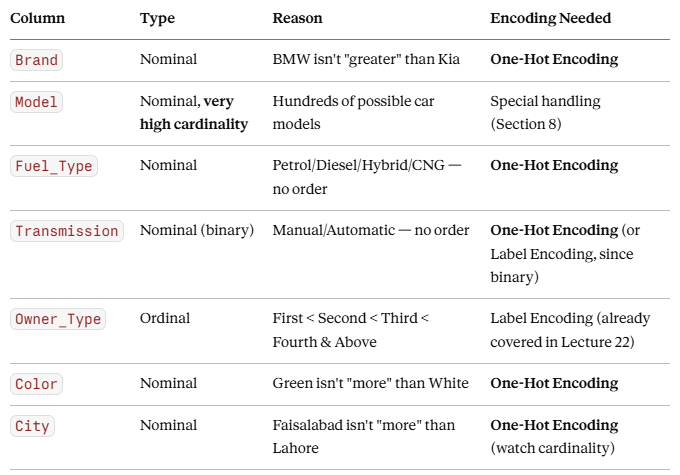

Why Do We Need One-Hot Encoding? (Recap of the Problem)
**bold text**
If we Label Encode Fuel_Type from your dataset:

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Fuel_Type_LabelEncoded'] = le.fit_transform(df['Fuel_Type'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

A regression model would now assume

Petrol (3) = CNG (0) + Diesel (1) + Hybrid (2) — mathematically meaningless.

 One-Hot Encoding fixes this by creating a separate 0/1 column per category, so no numeric relationship is implied between fuel types.

**What is One-Hot Encoding?**

Definition: One-Hot Encoding converts each category in a column into its own binary column (containing only 0 or 1), where 1 means "this row belongs to this category" and 0 means "it does not."

**Method 1: pd.get_dummies() (Simplest, Most Common)**

In [ ]:
# One-Hot Encode Fuel_Type and Transmission from your dataset
df_ohe = pd.get_dummies(df, columns=['Fuel_Type', 'Transmission'])
print(df_ohe.head())
print(df_ohe.columns.tolist())

   Car_ID       Brand    Model  Year  Age_Years    Price  Kilometers_Driven  \
0       1         BMW       X5  2019          7  7134000              86551   
1       2         Kia  Picanto  2025          1  4025000               8577   
2       3     Hyundai   Santro  2011         15   300000             177666   
3       4       Honda   Accord  2008         18   300000             217370   
4       5  Volkswagen     Golf  2013         13   342000             145065   

             Owner_Type  Mileage_kmpl  Engine_CC  ...  Seats  Color  \
0           Third Owner          16.4       2500  ...      5  Green   
1  Fourth & Above Owner          11.3       1300  ...      7  White   
2           First Owner          14.9       1300  ...      5  Green   
3           First Owner          12.6       1200  ...      5  White   
4           First Owner          18.0       1300  ...      5  Brown   

         City Fuel_Type_CNG  Fuel_Type_Diesel  Fuel_Type_Electric  \
0  Faisalabad         False  

**Method 2: OneHotEncoder from Scikit-learn (Pipeline-Friendly)**

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Step 1: Create the encoder
ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')

# Step 2: Fit and transform selected nominal columns
encoded_array = ohe.fit_transform(df[['Fuel_Type', 'Transmission', 'Color']])

# Step 3: Convert back into a readable DataFrame
encoded_df = pd.DataFrame(
    encoded_array,
    columns=ohe.get_feature_names_out(['Fuel_Type', 'Transmission', 'Color'])
)

print(encoded_df.head())

   Fuel_Type_Diesel  Fuel_Type_Electric  Fuel_Type_Hybrid  Fuel_Type_Petrol  \
0               0.0                 0.0               0.0               1.0   
1               0.0                 0.0               0.0               1.0   
2               1.0                 0.0               0.0               0.0   
3               0.0                 0.0               0.0               1.0   
4               0.0                 0.0               0.0               1.0   

   Transmission_Manual  Color_Blue  Color_Brown  Color_Green  Color_Grey  \
0                  1.0         0.0          0.0          1.0         0.0   
1                  1.0         0.0          0.0          0.0         0.0   
2                  1.0         0.0          0.0          1.0         0.0   
3                  1.0         0.0          0.0          0.0         0.0   
4                  1.0         0.0          1.0          0.0         0.0   

   Color_Red  Color_Silver  Color_White  
0        0.0           0.0

***Merging Back with the Original Numerical Columns***

In [ ]:
numerical_cols = ['Year', 'Age_Years', 'Kilometers_Driven', 'Mileage_kmpl', 'Engine_CC', 'Power_bhp', 'Seats', 'Price']

final_df = pd.concat([df[numerical_cols].reset_index(drop=True), encoded_df], axis=1)
print(final_df.head())